# Kernel PCA — Nonlinear Dimensionality Reduction

## 1. Definition and intuition
PCA finds linear directions of maximum variance. Kernel PCA first represents similarities through a kernel, which is equivalent to an implicit feature map into a possibly high-dimensional feature space, and then performs PCA there. It can uncover nonlinear structure without explicitly constructing nonlinear features.

## 2. Mathematics
A kernel computes \(K_{ij}=k(x_i,x_j)=\langle\phi(x_i),\phi(x_j)\rangle\). Common examples include the RBF kernel \(k(x,x')=\exp(-\gamma\|x-x'\|^2)\) and polynomial kernels.

PCA in feature space requires centering the Gram matrix:
\[
K_c=K-\mathbf 1_n K/n-K\mathbf 1_n/n+\mathbf 1_n K\mathbf 1_n/n^2.
\]
The eigenvectors of the centered Gram matrix provide principal directions in feature space. For a new point, its kernel vector must be centered using training-set means before projection.

## 3. Why it works
A positive-semidefinite kernel behaves like an inner product in a feature space (the kernel trick). Applying PCA to that Gram matrix therefore performs linear PCA in the implicit feature space. This does not guarantee a useful low-dimensional representation: kernel and hyperparameter choices define the geometry.

## 4. Assumptions and failure modes
The similarity measure must reflect meaningful proximity. RBF `gamma` that is too small makes points nearly identical; too large makes the kernel nearly diagonal. Kernel PCA can be memory-heavy because a dense n×n Gram matrix uses O(n²) memory.

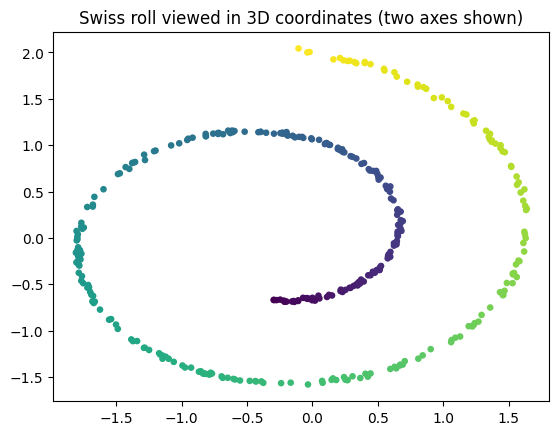

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import KernelPCA
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler

SEED = 42
X, color = make_swiss_roll(n_samples=350, noise=0.08, random_state=SEED)
X = StandardScaler().fit_transform(X)
plt.scatter(X[:, 0], X[:, 2], c=color, cmap="viridis", s=14)
plt.title("Swiss roll viewed in 3D coordinates (two axes shown)")
plt.show()


## 5. Kernel PCA from scratch (RBF kernel)

The implementation uses a centered training Gram matrix and a correctly centered cross-kernel for out-of-sample transformation. Eigenvector signs are arbitrary.

In [2]:
def rbf_kernel(X, Y=None, gamma=None):
    X = np.asarray(X, dtype=float)
    Y = X if Y is None else np.asarray(Y, dtype=float)
    if gamma is None:
        gamma = 1.0 / X.shape[1]
    d2 = pairwise_distances(X, Y, metric="sqeuclidean")
    return np.exp(-gamma * d2)

def fit_kernel_pca(X, n_components=2, gamma=1.0):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) < 2 or n_components < 1 or n_components >= len(X) or gamma <= 0:
        raise ValueError("Invalid X, n_components, or gamma")
    K = rbf_kernel(X, gamma=gamma)
    col_mean = K.mean(axis=0)
    grand_mean = K.mean()
    Kc = K - K.mean(axis=1, keepdims=True) - col_mean[None, :] + grand_mean
    eigvals, eigvecs = np.linalg.eigh(Kc)
    order = np.argsort(eigvals)[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]
    keep = eigvals[:n_components] > 1e-10
    vals = eigvals[:n_components][keep]
    vecs = eigvecs[:, :n_components][:, keep]
    if len(vals) == 0:
        raise ValueError("No positive eigenvalues; try a different gamma")
    return {"X_fit": X, "gamma": gamma, "train_col_mean": col_mean,
            "train_grand_mean": grand_mean, "eigenvalues": vals,
            "eigenvectors": vecs}

def transform_kernel_pca(X_new, model):
    K_new = rbf_kernel(X_new, model["X_fit"], gamma=model["gamma"])
    K_new_centered = (K_new - K_new.mean(axis=1, keepdims=True)
                      - model["train_col_mean"][None, :] + model["train_grand_mean"])
    return K_new_centered @ model["eigenvectors"] / np.sqrt(model["eigenvalues"])[None, :]

kp = fit_kernel_pca(X, n_components=2, gamma=1.0)
Z_scratch = transform_kernel_pca(X, kp)
print("Scratch embedding shape:", Z_scratch.shape)
print("Kernel PCA eigenvalues:", np.round(kp["eigenvalues"], 3))


Scratch embedding shape: (350, 2)
Kernel PCA eigenvalues: [25.308 23.006]


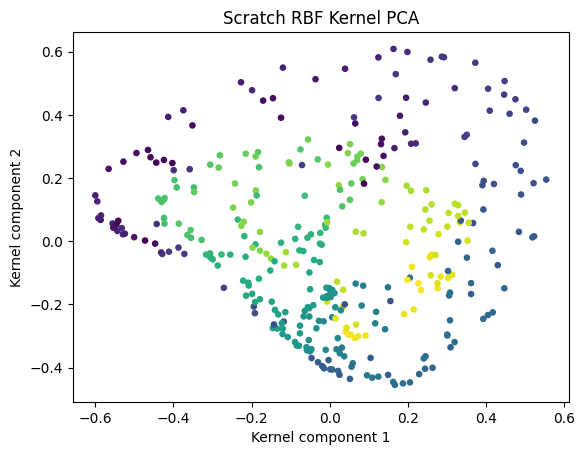

In [3]:
plt.scatter(Z_scratch[:, 0], Z_scratch[:, 1], c=color, cmap="viridis", s=14)
plt.title("Scratch RBF Kernel PCA")
plt.xlabel("Kernel component 1"); plt.ylabel("Kernel component 2"); plt.show()


## 6. Compare with scikit-learn

Compare embeddings visually and compare the pairwise distances between embeddings. The coordinate axes can differ by sign or orientation.

In [4]:
sk_kp = KernelPCA(n_components=2, kernel="rbf", gamma=1.0, eigen_solver="arpack", random_state=SEED)
Z_sk = sk_kp.fit_transform(X)
print("sklearn embedding shape:", Z_sk.shape)
print("Embedding distance-matrix correlation:",
      np.corrcoef(pairwise_distances(Z_scratch).ravel(), pairwise_distances(Z_sk).ravel())[0, 1])
assert Z_sk.shape == Z_scratch.shape
assert np.isfinite(Z_sk).all() and np.isfinite(Z_scratch).all()


sklearn embedding shape: (350, 2)
Embedding distance-matrix correlation: 1.0


## 7. Hyperparameters, complexity and scaling
- `kernel`: RBF, polynomial, sigmoid and precomputed kernels encode different geometries.
- `gamma`: controls RBF locality; tune using downstream validation or visualization objectives, not visual aesthetics alone.
- `n_components`: retained dimensions.
- Dense kernel construction/storage costs \(O(n^2d)\) time and \(O(n^2)\) memory; dense eigendecomposition is \(O(n^3)\). Transforming m points costs roughly \(O(mnd)\) for RBF evaluation plus \(O(mnk)\) projection.
- For large n, consider approximate kernel features (e.g. random Fourier features), Nyström approximations, or linear methods.
- GPU: pairwise kernels and matrix multiplication can be accelerated, but the dense Gram matrix memory remains limiting.

## 8. Synthesis and tests

Kernel PCA applies PCA to a centered similarity matrix. It can capture nonlinear geometry, but kernel choice is the model choice and n-squared memory is the major scaling barrier.

In [5]:
assert np.isfinite(Z_scratch).all()
assert np.isfinite(kp["eigenvalues"]).all()
try:
    fit_kernel_pca(np.array([1,2,3]), 2)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All Kernel PCA checks passed.")


All Kernel PCA checks passed.
